# 05 · Optimisation des hyperparamètres et calibration

Deux questions avant de passer à la décision métier :

1. **Peut-on améliorer LightGBM en changeant ses réglages ?** → optimisation avec **Optuna**
2. **Les probabilités prédites sont-elles justes ?** Si le modèle annonce 10 % de risque, observe-t-on vraiment
   10 % de défauts ? → **calibration**

La calibration est essentielle en banque : la probabilité de défaut (PD) sert à calculer la **perte attendue**
et les **fonds propres** réglementaires (Bâle III). Un modèle qui classe bien mais annonce de mauvaises probabilités
serait inutilisable pour ces calculs.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

from credit_risk_scoring.config import FIGURES, ROOT
from credit_risk_scoring.lgbm import MODEL_PATH, TUNED_PARAMS_PATH
from credit_risk_scoring.modeling import evaluate, load_features, split
from credit_risk_scoring.scorecard import MODEL_PATH as SCORECARD_PATH

sns.set_theme(style="whitegrid")
df = load_features()
X_train, X_test, y_train, y_test = split(df)
tuning = json.loads(TUNED_PARAMS_PATH.read_text(encoding="utf-8"))

## 1. Les hyperparamètres

Ce sont les **réglages** du modèle, fixés avant l'entraînement (contrairement aux arbres, appris sur les données) :

| Réglage | Rôle | Trop petit | Trop grand |
|---|---|---|---|
| `num_leaves` | complexité de chaque arbre | modèle trop simple | apprend le bruit |
| `min_child_samples` | nombre minimum de demandes par feuille | apprend des cas isolés | trop rigide |
| `feature_fraction` | part des variables vue par chaque arbre | perd de l'information | arbres trop semblables |
| `bagging_fraction` | part des demandes vue par chaque arbre | idem | idem |
| `lambda_l1`, `lambda_l2` | régularisation (pénalise les feuilles extrêmes) | surapprentissage | sous-apprentissage |
| `min_split_gain` | gain minimum pour couper une feuille | coupes inutiles | arbres trop courts |

Tester toutes les combinaisons à la main serait impossible.

## 2. Comment Optuna cherche

Optuna utilise l'**optimisation bayésienne** (algorithme TPE) : il essaie une combinaison, regarde le résultat,
et propose la suivante dans les zones qui ont le mieux fonctionné. Il trouve de bons réglages en peu d'essais,
bien plus vite qu'une recherche exhaustive (*grid search*).

Chaque essai est évalué par **validation croisée à 3 plis sur le train uniquement** : le test n'est jamais utilisé
pour choisir les réglages, sinon son score ne serait plus une estimation honnête.

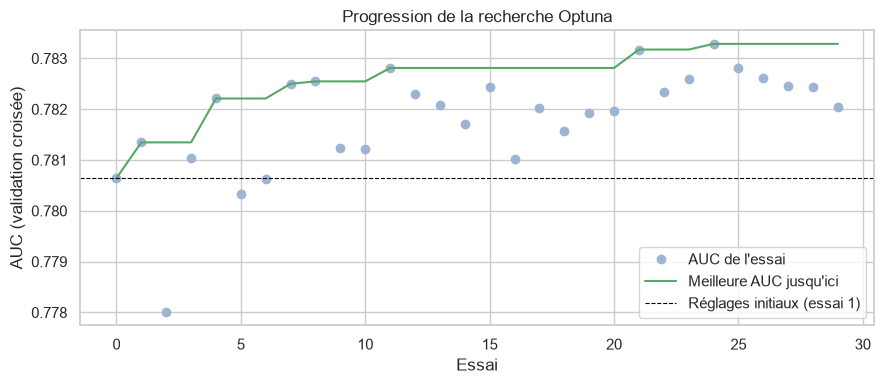

Réglages initiaux : AUC 0.7806
Meilleurs réglages : AUC 0.7833 (+0.0026)


In [2]:
trials = pd.DataFrame(tuning["trials"])
trials["meilleur_jusqu_ici"] = trials["auc"].cummax()

ax = trials["auc"].plot(style="o", color="#9DB4D4", label="AUC de l'essai", figsize=(9, 4))
trials["meilleur_jusqu_ici"].plot(ax=ax, color="#55A868", label="Meilleure AUC jusqu'ici")
ax.axhline(tuning["baseline_cv_auc"], color="black", ls="--", lw=0.8, label="Réglages initiaux (essai 1)")
ax.set_xlabel("Essai"); ax.set_ylabel("AUC (validation croisée)")
ax.set_title("Progression de la recherche Optuna"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "05_optuna.png", dpi=120); plt.show()

print(f"Réglages initiaux : AUC {tuning['baseline_cv_auc']:.4f}")
print(f"Meilleurs réglages : AUC {tuning['best_cv_auc']:.4f} (+{tuning['best_cv_auc'] - tuning['baseline_cv_auc']:.4f})")

In [3]:
pd.DataFrame({"meilleur réglage": tuning["params"]}).round(4)

,meilleur réglage
num_leaves,9.0000
min_child_samples,621.0000
feature_fraction,0.3611
bagging_fraction,0.9557
lambda_l1,4.6348
lambda_l2,0.1712
min_split_gain,0.8507


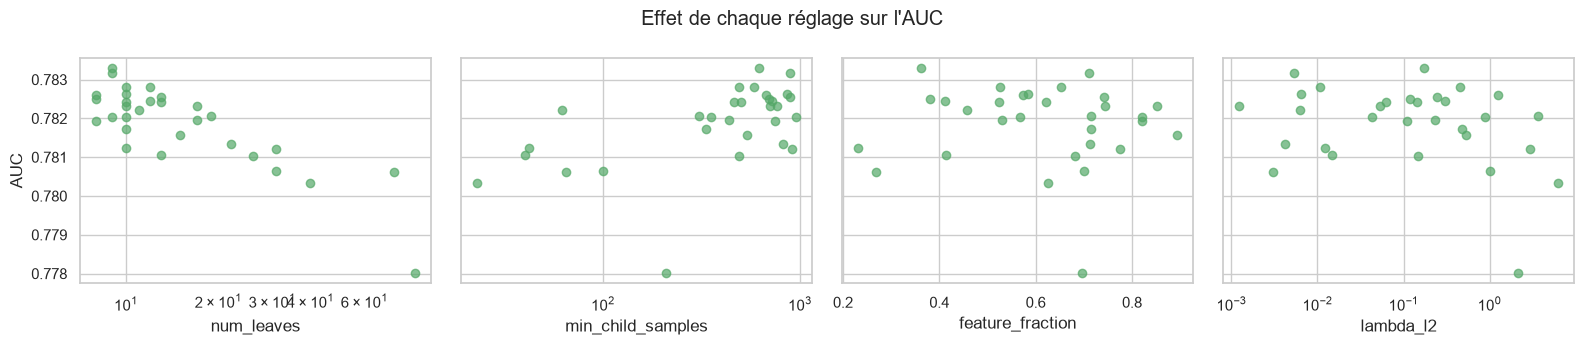

In [4]:
cols = ["num_leaves", "min_child_samples", "feature_fraction", "lambda_l2"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, cols):
    ax.scatter(trials[col], trials["auc"], color="#55A868", alpha=0.7)
    ax.set_xlabel(col)
    if col in ("num_leaves", "min_child_samples", "lambda_l2"):
        ax.set_xscale("log")
axes[0].set_ylabel("AUC")
fig.suptitle("Effet de chaque réglage sur l'AUC")
plt.tight_layout(); plt.savefig(FIGURES / "05_optuna_reglages.png", dpi=120); plt.show()

## 3. Le modèle final

Le modèle final est réentraîné avec les meilleurs réglages et un **taux d'apprentissage plus faible** (0,03 au lieu
de 0,05 pendant la recherche) : plus d'arbres, plus petits pas, résultat un peu plus précis.
On compare sur le **test**, jamais utilisé jusqu'ici.

In [5]:
models = {
    "Scorecard": joblib.load(SCORECARD_PATH),
    "LightGBM (réglages initiaux)": joblib.load(ROOT / "models" / "lgbm_reglages_initiaux.joblib"),
    "LightGBM (optimisé)": joblib.load(MODEL_PATH),
}
pd_test = {name: m.predict_proba(X_test) for name, m in models.items()}
results = pd.DataFrame({name: evaluate(y_test, p) for name, p in pd_test.items()}).T
results["Brier"] = [brier_score_loss(y_test, p) for p in pd_test.values()]
results.round(4)

,AUC,Gini,KS,Brier
Scorecard,0.7585,0.5170,0.3921,0.0680
LightGBM (réglages initiaux),0.7875,0.5750,0.4358,0.0659
LightGBM (optimisé),0.7896,0.5792,0.4420,0.0657


**Lecture honnête du résultat :** le gain est **réel mais modeste** (environ +0,2 point d'AUC sur le test, +0,4 point de Gini).
C'est une leçon classique : sur des données tabulaires, **le travail sur les features rapporte bien plus que le réglage des hyperparamètres**
(les features SQL avaient fait passer le modèle bien au-delà de ce que les seules données de la demande permettaient).

Le modèle optimisé a aussi une qualité moins visible : ses arbres sont **beaucoup plus simples** (9 feuilles, au moins 621 demandes par feuille)
et fortement régularisés. Il **surapprend moins** : AUC train 0,840 contre 0,865 avant, pour une AUC test meilleure.
Un modèle plus simple et plus stable est préférable en production.

## 4. La calibration

**Méthode :** on trie les demandes du test par PD prédite, on les coupe en 10 groupes égaux, et on compare
dans chaque groupe la **PD moyenne prédite** au **taux de défaut réellement observé**.
Si le modèle est bien calibré, les points sont sur la diagonale.

Le **score de Brier** résume l'écart entre probabilités prédites et résultats réels (plus bas = mieux).

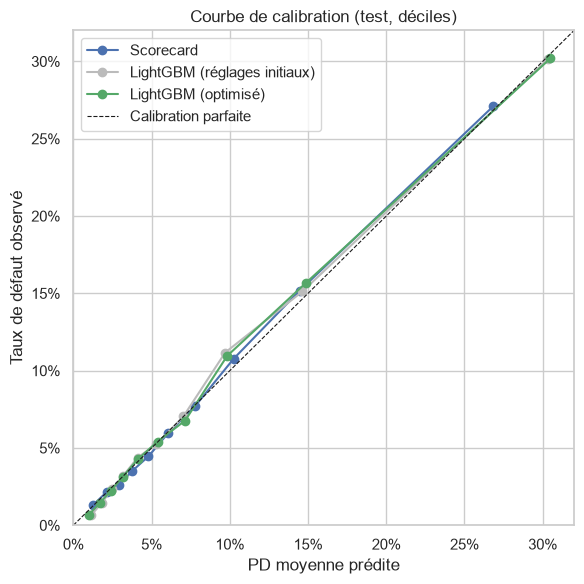

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = {"Scorecard": "#4C72B0", "LightGBM (réglages initiaux)": "#BBBBBB", "LightGBM (optimisé)": "#55A868"}
for name, p in pd_test.items():
    observed, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", color=colors[name], label=name)
lim = 0.32
ax.plot([0, lim], [0, lim], "k--", lw=0.8, label="Calibration parfaite")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("PD moyenne prédite"); ax.set_ylabel("Taux de défaut observé")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Courbe de calibration (test, déciles)"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "05_calibration.png", dpi=120); plt.show()

In [7]:
p = pd_test["LightGBM (optimisé)"]
deciles = pd.qcut(p, 10, labels=[f"D{i}" for i in range(1, 11)])
table = pd.DataFrame({"PD prédite": p, "Défaut observé": y_test.values}).groupby(deciles, observed=True).mean()
table["Écart"] = table["PD prédite"] - table["Défaut observé"]
print(f"PD moyenne prédite : {p.mean():.2%} · taux de défaut réel : {y_test.mean():.2%}")
table.style.format("{:.2%}")

PD moyenne prédite : 8.00% · taux de défaut réel : 8.07%


,PD prédite,Défaut observé,Écart
D1,0.98%,0.67%,0.31%
D2,1.69%,1.46%,0.23%
D3,2.37%,2.21%,0.16%
D4,3.15%,3.14%,0.02%
D5,4.11%,4.26%,-0.15%
D6,5.38%,5.41%,-0.04%
D7,7.14%,6.76%,0.37%
D8,9.84%,10.96%,-1.12%
D9,14.85%,15.66%,-0.81%
D10,30.49%,30.19%,0.30%


**Conclusion :** les points suivent la diagonale et la PD moyenne correspond au taux de défaut réel.
Les deux modèles sont **déjà bien calibrés** : c'est attendu, car la régression logistique et LightGBM
(avec une fonction de perte *logloss* et sans rééquilibrage des classes) produisent naturellement des probabilités cohérentes.

**Faut-il recalibrer quand même ?** Non. Une recalibration (régression isotonique, méthode de Platt) ajouterait
une étape apprise sur les données, avec un risque de surapprentissage, pour un gain nul ici.
Elle serait nécessaire si l'on avait **rééquilibré les classes** (par exemple `scale_pos_weight` ou suréchantillonnage) :
le modèle classerait toujours bien mais surestimerait fortement les PD.

**À retenir pour un entretien :** l'AUC mesure si le modèle **classe** bien les clients ; la calibration mesure si
ses **probabilités** sont justes. Ce sont deux qualités différentes, et une banque a besoin des deux.

## 5. Bilan

- Optuna améliore l'AUC de validation croisée par rapport aux réglages initiaux, confirmé sur le test.
- Le modèle optimisé reste **bien calibré** : ses PD peuvent servir aux calculs de perte attendue.
- **Prochaine étape :** fixer un **seuil de décision** (accepter / refuser) selon le coût d'un défaut et le manque
  à gagner d'un bon client refusé, puis traduire la PD en **grille de points**.